# Методы оптимизации в машинном обучении

# Задание 1

In [1]:
!python -m pytest presubmit_tests.py::test_line_search

============================= test session starts ==============================
platform linux -- Python 3.13.18, pytest-8.4.2, pluggy-1.7.0
rootdir: /content
plugins: langsmith-0.14.17, typeguard-4.6.0, anyio-4.16.0, platformdirs-4.14.3
collected 1 item                                                               

presubmit_tests.py .                                                     [100%]

============================== 1 passed in 0.34s ===============================


# Задание 2

In [2]:
!python -m pytest presubmit_tests.py::test_gd_basic presubmit_tests.py::test_gd_1d

============================= test session starts ==============================
platform linux -- Python 3.13.18, pytest-8.4.2, pluggy-1.7.0
rootdir: /content
plugins: langsmith-0.14.17, typeguard-4.6.0, anyio-4.16.0, platformdirs-4.14.3
collected 2 items                                                              

presubmit_tests.py ..                                                    [100%]

============================== 2 passed in 0.41s ===============================


# Задание 3

/content/plot_trajectory_2d.py:30: UserWarning: The following kwargs were not used by contour: 'linewidth'
  CS = plt.contour(X, Y, Z, levels=levels, colors='k', linewidth=4.0)


kappa = 1.0 method = Constant start = [3. 2.] iterations = 573 success
kappa = 1.0 method = Constant start = [-3.  2.] iterations = 573 success
kappa = 1.0 method = Armijo start = [3. 2.] iterations = 1 success
kappa = 1.0 method = Armijo start = [-3.  2.] iterations = 1 success
kappa = 1.0 method = Wolfe start = [3. 2.] iterations = 1 success
kappa = 1.0 method = Wolfe start = [-3.  2.] iterations = 1 success


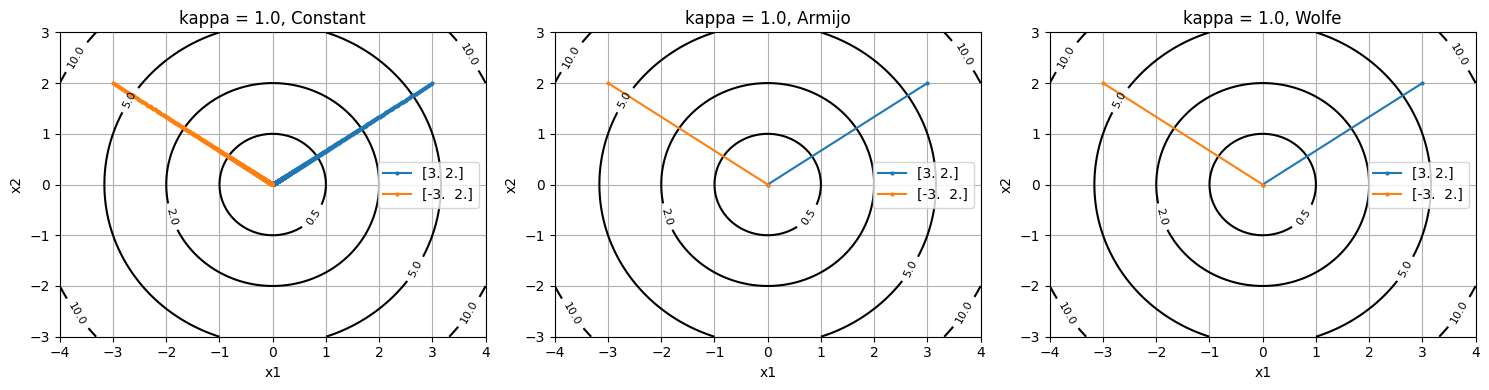

kappa = 10.0 method = Constant start = [3. 2.] iterations = 383 success
kappa = 10.0 method = Constant start = [-3.  2.] iterations = 383 success
kappa = 10.0 method = Armijo start = [3. 2.] iterations = 19 success
kappa = 10.0 method = Armijo start = [-3.  2.] iterations = 19 success
kappa = 10.0 method = Wolfe start = [3. 2.] iterations = 3 success
kappa = 10.0 method = Wolfe start = [-3.  2.] iterations = 3 success


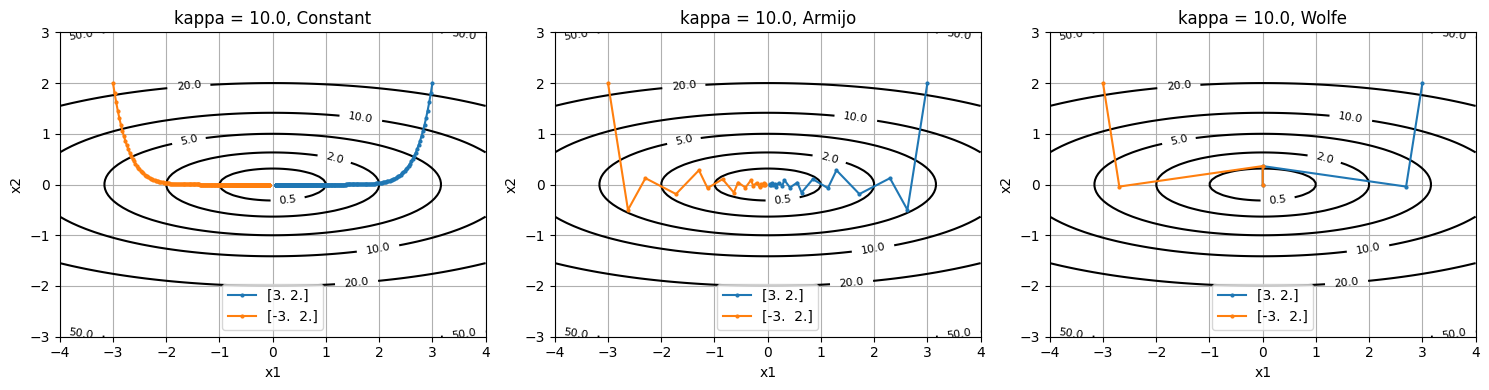

kappa = 100.0 method = Constant start = [3. 2.] iterations = 155 success
kappa = 100.0 method = Constant start = [-3.  2.] iterations = 155 success
kappa = 100.0 method = Armijo start = [3. 2.] iterations = 87 success
kappa = 100.0 method = Armijo start = [-3.  2.] iterations = 87 success
kappa = 100.0 method = Wolfe start = [3. 2.] iterations = 3 success
kappa = 100.0 method = Wolfe start = [-3.  2.] iterations = 3 success


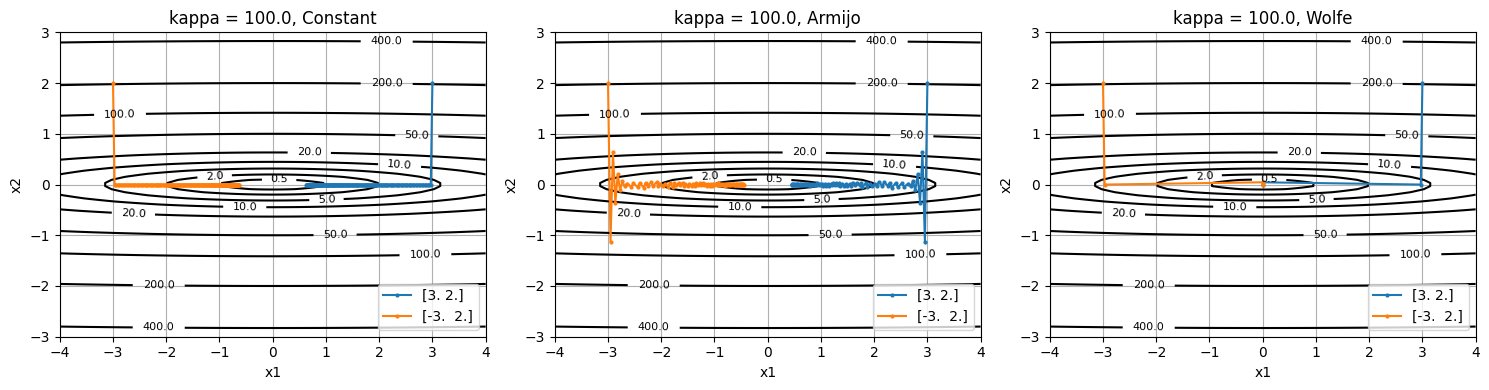

In [3]:
%matplotlib inline
import numpy as np
import matplotlib.pyplot as plt
from optimization import gradient_descent, newton
from oracles import QuadraticOracle
from plot_trajectory_2d import plot_levels, plot_trajectory

matrices = [np.diag([1.0, 1.0]), np.diag([1.0, 10.0]), np.diag([1.0, 100.0])]
starts = [np.array([3.0, 2.0]), np.array([-3.0, 2.0])]
methods = [{'method': 'Constant', 'c': 0.01}, {'method': 'Armijo'}, {'method': 'Wolfe'}]

for A in matrices:
    oracle = QuadraticOracle(A, np.zeros(2))
    fig, axes = plt.subplots(1, 3, figsize=(15, 4))
    for j in range(3):
        plt.sca(axes[j])
        plot_levels(oracle.func, xrange=[-4, 4], yrange=[-3, 3],
                    levels=[0.5, 2, 5, 10, 20, 50, 100, 200, 400])
        for x0 in starts:
            x, msg, history = gradient_descent(oracle, x0, tolerance=1e-5,
                    max_iter=1000, line_search_options=methods[j], trace=True)
            points = np.array(history['x'])
            plt.plot(points[:, 0], points[:, 1], '-o', markersize=2,
                     linewidth=1.5, label=str(x0))
            print('kappa =', A[1, 1], 'method =', methods[j]['method'],
                  'start =', x0, 'iterations =', len(history['func']) - 1, msg)
        plt.title('kappa = ' + str(A[1, 1]) + ', ' + methods[j]['method'])
        plt.xlabel('x1')
        plt.ylabel('x2')
        plt.legend()
    plt.tight_layout()
    plt.show()

**Вывод:** *При большем числе обусловленности линии уровня вытягиваются, и градиентный спуск чаще движется зигзагами. Постоянный маленький шаг может быть очень медленным, а адаптивные шаги обычно позволяют сократить число итераций. Начальная точка влияет на длину траектории.*

# Задание 4

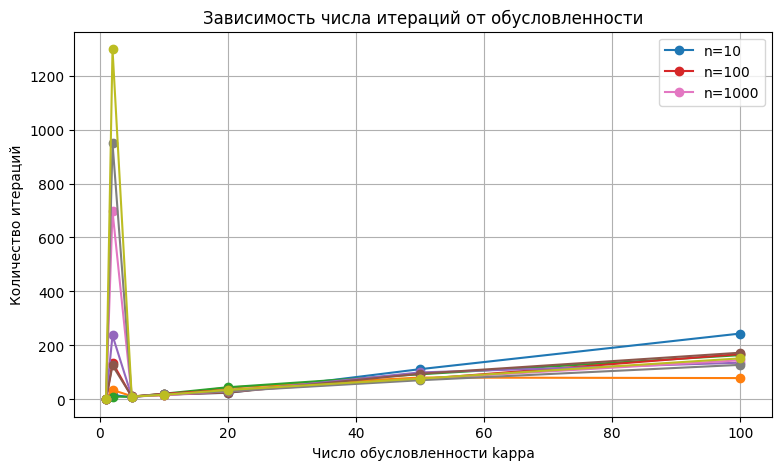

In [4]:
import scipy.sparse

np.random.seed(42)
sizes = [10, 100, 1000]
kappas = [1, 2, 5, 10, 20, 50, 100]
plt.figure(figsize=(9, 5))

for n in sizes:
    for repeat in range(3):
        iterations = []
        for kappa in kappas:
            diag = np.random.uniform(1, kappa, n)
            diag[0] = 1
            diag[-1] = kappa
            A = scipy.sparse.diags(diag)
            b = np.random.randn(n)
            oracle = QuadraticOracle(A, b)
            x, msg, history = gradient_descent(oracle, np.zeros(n),
                    tolerance=1e-5, max_iter=2000,
                    line_search_options={'method': 'Armijo'}, trace=True)
            iterations.append(len(history['func']) - 1)
        plt.plot(kappas, iterations, '-o', linewidth=1.5,
                 label='n=' + str(n) if repeat == 0 else None)
plt.xlabel('Число обусловленности kappa')
plt.ylabel('Количество итераций')
plt.title('Зависимость числа итераций от обусловленности')
plt.legend()
plt.grid()
plt.show()

**Вывод:** *При увеличении числа обусловленности число итераций в среднем растёт. Размерность влияет на конкретную случайную задачу, но обусловленность обычно определяет скорость сходимости сильнее.*

# Задание 5

In [5]:
!python -m pytest presubmit_tests.py::test_newton_basic presubmit_tests.py::test_newton_1d presubmit_tests.py::test_newton_fail

============================= test session starts ==============================
platform linux -- Python 3.13.18, pytest-8.4.2, pluggy-1.7.0
rootdir: /content
plugins: langsmith-0.14.17, typeguard-4.6.0, anyio-4.16.0, platformdirs-4.14.3
collected 3 items                                                              

presubmit_tests.py ...                                                   [100%]

============================== 3 passed in 0.36s ===============================


# Задание 6

## Справка: функция, градиент и гессиан логистической регрессии

Ниже приведены формулы из задания 6 — пользуйтесь ими как шпаргалкой при реализации оракула (задание 7).

Обозначим $z := b \odot (Ax) \in \mathbb{R}^m$, где $\odot$ — поэлементное умножение, а все скалярные функции ($\ln$, $\exp$, $\sigma$) применяются к векторам поэлементно. Тогда

$$f(x) = \frac{1}{m}\, \mathbf{1}_m^T \ln\!\big(1 + e^{-z}\big) + \frac{\lambda}{2} \|x\|_2^2,$$

$$\nabla f(x) = -\frac{1}{m}\, A^T \big( b \odot \sigma(-z) \big) + \lambda x, \qquad \sigma(t) := \frac{1}{1 + e^{-t}},$$

$$\nabla^2 f(x) = \frac{1}{m}\, A^T\, \operatorname{Diag}(s)\, A + \lambda I_n, \qquad s := \sigma(-z) \odot \big(1 - \sigma(-z)\big).$$

**Как считать это в numpy/scipy (без переполнений и с поддержкой разреженных матриц):**

* $\ln(1 + e^{-z})$ — функция `np.logaddexp(0, -z)`: она эквивалентна «в лоб», но не переполняется при больших $|z|$;
* сигмоида $\sigma(z)$ — функция `scipy.special.expit(z)`;
* произведения $Ax$ и $A^T y$ — методы `A.dot(x)` и `A.T.dot(y)`: они одинаково работают и для плотных матриц `np.array`, и для разреженных `scipy.sparse.csr_matrix`;
* в гессиане произведение $A^T\, \operatorname{Diag}(s)\, A$ не нужно считать через явную диагональную матрицу — достаточно поэлементно домножить строки $A$ на вектор $s$: для плотной матрицы это `A * s[:, None]`, для разреженной — метод `A.multiply(s[:, None])` (тип матрицы проверяется функцией `scipy.sparse.issparse`);
* слагаемое $\lambda I_n$ — это `regcoef * np.eye(n)`.

## Решение

Пусть $z=b\odot(Ax)$, $q=\sigma(-z)$, $D=\operatorname{Diag}(q\odot(1-q))$, $\mathbf{1}$ — вектор единиц. Тогда

$$f(x)=\frac1m\mathbf{1}^T\log(\mathbf{1}+\exp(-z))+\frac\lambda2 x^Tx,$$

$$\nabla f(x)=-\frac1m A^T(b\odot q)+\lambda x,$$

$$\nabla^2 f(x)=\frac1m A^T D A+\lambda I.$$

# Задание 7

In [6]:
!python -m pytest presubmit_tests.py::test_log_reg_usual presubmit_tests.py::test_grad_finite_diff_1 presubmit_tests.py::test_grad_finite_diff_2 presubmit_tests.py::test_hess_finite_diff_1 presubmit_tests.py::test_hess_finite_diff_2

============================= test session starts ==============================
platform linux -- Python 3.13.18, pytest-8.4.2, pluggy-1.7.0
rootdir: /content
plugins: langsmith-0.14.17, typeguard-4.6.0, anyio-4.16.0, platformdirs-4.14.3
collected 5 items                                                              

presubmit_tests.py .....                                                 [100%]

============================== 5 passed in 0.32s ===============================


# Задание 8

Ошибка градиента: 8.183471599790933e-09
Ошибка гессиана: 4.070763658964262e-06
Ошибка градиента: 1.314873965736035e-08
Ошибка гессиана: 6.175855631826917e-06
Набор: data/w8a.txt полный размер: (2000, 60)
Градиентный спуск success итераций: 58
Ньютон success итераций: 3


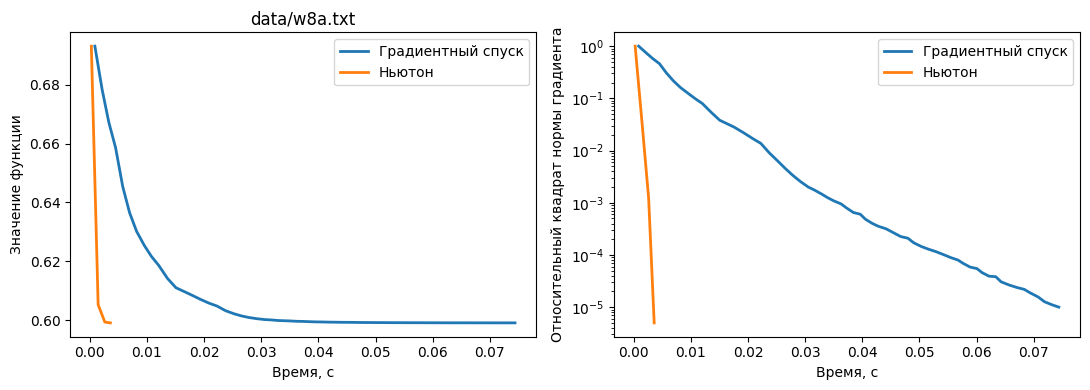

Набор: data/gisette_scale.bz2 полный размер: (2000, 60)
Градиентный спуск success итераций: 2417
Ньютон success итераций: 4


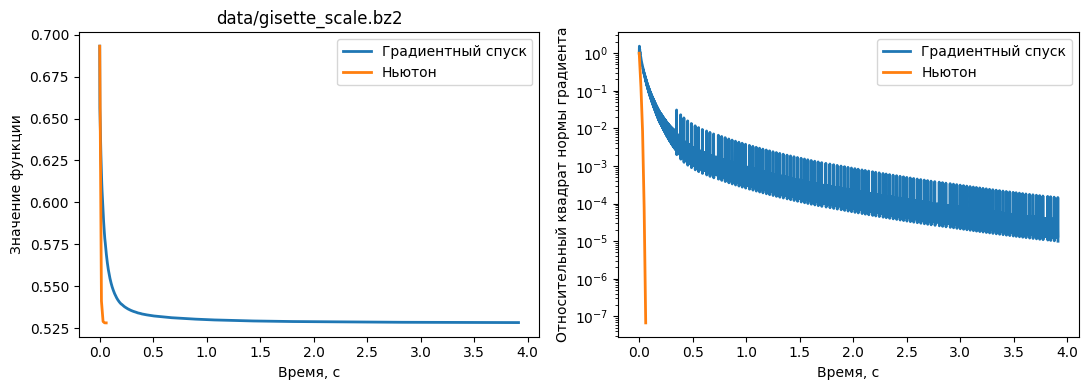

Набор: data/real-sim.bz2 полный размер: (2000, 60)
Градиентный спуск success итераций: 37
Ньютон success итераций: 3


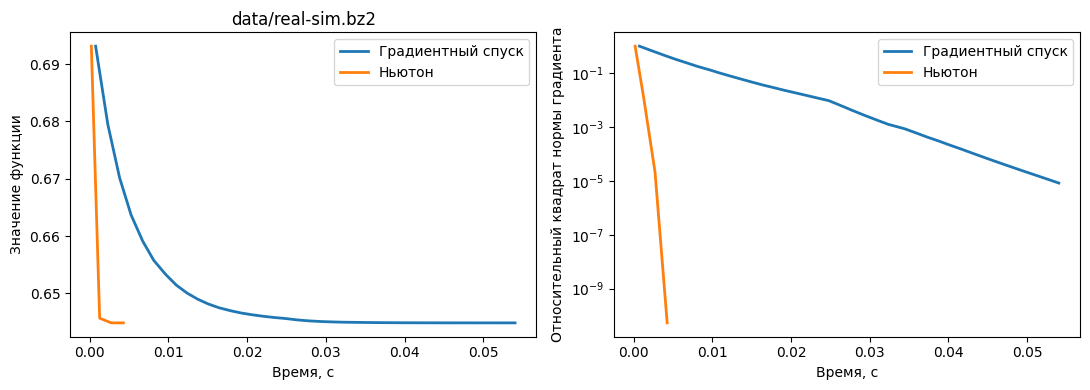

In [8]:
from sklearn.datasets import load_svmlight_file
from oracles import LogRegL2Oracle, grad_finite_diff, hess_finite_diff

# Проверка аналитических производных на маленьком примере
np.random.seed(42)
A = np.random.randn(8, 3)
b = np.random.choice([-1, 1], size=8)
oracle = LogRegL2Oracle(A, b, 0.1)
for x in [np.zeros(3), np.array([0.2, -0.1, 0.3])]:
    print('Ошибка градиента:', np.linalg.norm(oracle.grad(x) - grad_finite_diff(oracle.func, x)))
    print('Ошибка гессиана:', np.linalg.norm(oracle.hess(x) - hess_finite_diff(oracle.func, x)))

files = ['data/w8a.txt', 'data/gisette_scale.bz2', 'data/real-sim.bz2']

for filename in files:
    A, b = load_svmlight_file(filename)
    # Уменьшил размер датасетов, иначе выполняется очень долго
    A = A[:2000, :60].tocsr()
    b = b[:2000]
    # В некоторых наборах метки 0/1, переводим их в -1/+1
    b = np.where(b > 0, 1, -1)
    m, n = A.shape
    oracle = LogRegL2Oracle(A, b, 1 / m)
    x0 = np.zeros(n)
    print('Набор:', filename, 'полный размер:', A.shape)
    results = []
    for name, method in [('Градиентный спуск', gradient_descent), ('Ньютон', newton)]:
        x, msg, history = method(oracle, x0, trace=True)
        results.append((name, history))
        print(name, msg, 'итераций:', len(history['func']) - 1)
    plt.figure(figsize=(11, 4))
    plt.subplot(1, 2, 1)
    for name, history in results:
        plt.plot(history['time'], history['func'], linewidth=2, label=name)
    plt.xlabel('Время, с')
    plt.ylabel('Значение функции')
    plt.title(filename)
    plt.legend()
    plt.subplot(1, 2, 2)
    for name, history in results:
        norms = np.array(history['grad_norm'])
        relative = norms**2 / norms[0]**2
        plt.semilogy(history['time'], relative, linewidth=2, label=name)
    plt.xlabel('Время, с')
    plt.ylabel('Относительный квадрат нормы градиента')
    plt.legend()
    plt.tight_layout()
    plt.show()

**Вывод:** *Метод Ньютона обычно требует меньше итераций, поскольку учитывает кривизну функции, но каждая его итерация существенно дороже. Градиентный спуск делает дешёвые итерации и лучше подходит для задач с очень большим количеством признаков.*